Linear SVM Accuracy: 0.7094017094017094
              precision    recall  f1-score   support

           1       0.71      1.00      0.83        83
           2       0.00      0.00      0.00        34

    accuracy                           0.71       117
   macro avg       0.35      0.50      0.41       117
weighted avg       0.50      0.71      0.59       117

Non-Linear SVM Accuracy: 0.6837606837606838
              precision    recall  f1-score   support

           1       0.70      0.96      0.81        83
           2       0.00      0.00      0.00        34

    accuracy                           0.68       117
   macro avg       0.35      0.48      0.41       117
weighted avg       0.50      0.68      0.58       117



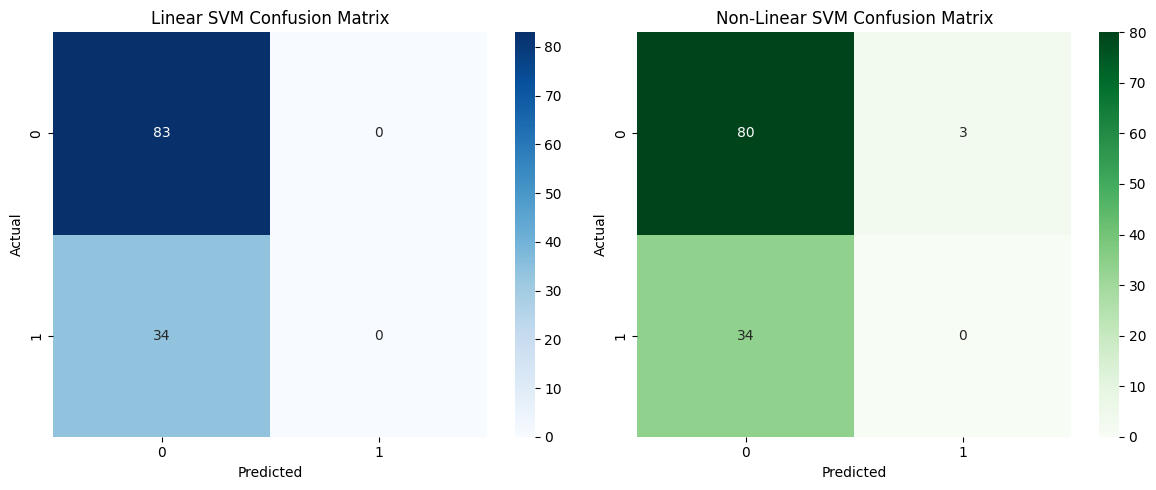

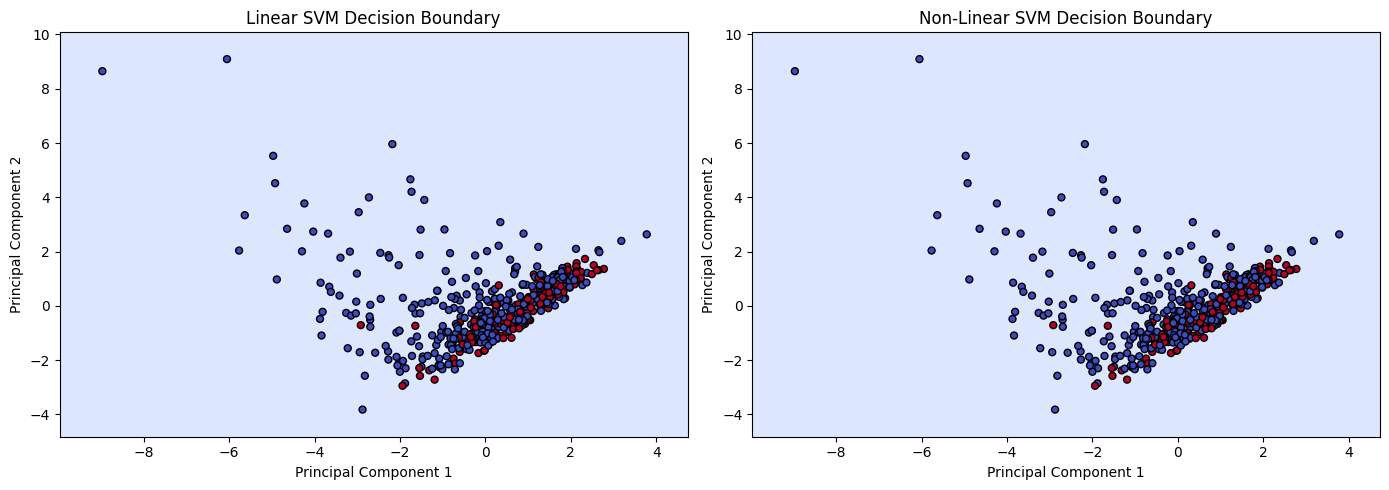

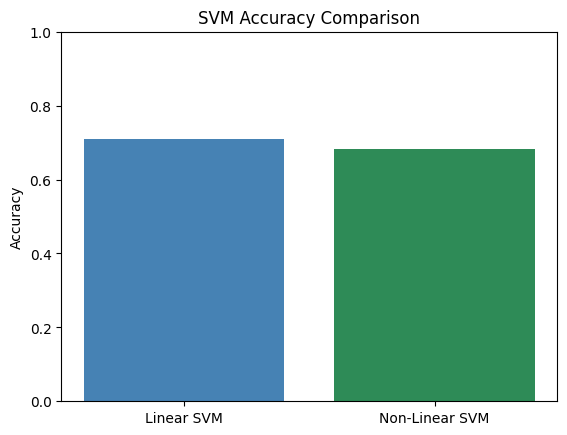

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("Indian_Liver_Patient_Dataset(ILPD).csv")

df["gender"] = df["gender"].map({"Male": 1, "Female": 0})
df = df.dropna(subset=["is_patient"])

X = df.drop("is_patient", axis=1)
y = df["is_patient"]

X = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X),
    columns=X.columns
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train_scaled, y_train)
linear_pred = linear_svm.predict(X_test_scaled)

rbf_svm = SVC(kernel="rbf")
rbf_svm.fit(X_train_scaled, y_train)
rbf_pred = rbf_svm.predict(X_test_scaled)

print("Linear SVM Accuracy:", accuracy_score(y_test, linear_pred))
print(classification_report(y_test, linear_pred, zero_division=0))

print("Non-Linear SVM Accuracy:", accuracy_score(y_test, rbf_pred))
print(classification_report(y_test, rbf_pred, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, linear_pred),
    annot=True, fmt="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("Linear SVM Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, rbf_pred),
    annot=True, fmt="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("Non-Linear SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

linear_graph = SVC(kernel="linear")
linear_graph.fit(X_train_pca, y_train)

rbf_graph = SVC(kernel="rbf")
rbf_graph.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = __import__("numpy").meshgrid(
    __import__("numpy").arange(x_min, x_max, 0.1),
    __import__("numpy").arange(y_min, y_max, 0.1)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], linear_graph, "Linear SVM Decision Boundary"),
    (axes[1], rbf_graph, "Non-Linear SVM Decision Boundary")
]:
    Z = model.predict(__import__("numpy").c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(
        X_train_pca[:, 0], X_train_pca[:, 1],
        c=y_train, cmap="coolwarm", edgecolors="black", s=25
    )
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

accuracies = [
    accuracy_score(y_test, linear_pred),
    accuracy_score(y_test, rbf_pred)
]

plt.bar(
    ["Linear SVM", "Non-Linear SVM"],
    accuracies,
    color=["steelblue", "seagreen"]
)
plt.title("SVM Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

